In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

# Project paths
PROJECT_DIR = Path.home() / "Climate-Change-Awareness-Dashboard"

PRECIPITATION_DIR = PROJECT_DIR / "precipitation"

INTERIM_DIR = PRECIPITATION_DIR / "data" / "interim"

# Analysis period
START_YEAR = 1951
END_YEAR = 2025

print("Project directory:", PROJECT_DIR)
print("Interim data directory:", INTERIM_DIR)
print("Analysis period:", START_YEAR, "-", END_YEAR)

Project directory: /home/sharanya/Climate-Change-Awareness-Dashboard
Interim data directory: /home/sharanya/Climate-Change-Awareness-Dashboard/precipitation/data/interim
Analysis period: 1951 - 2025


In [2]:
#rainfall distribution analysis for all years 

distribution_results = []

for year in range(START_YEAR, END_YEAR + 1):

    file_path = INTERIM_DIR / f"imd_rainfall_{year}.csv"

    rainfall_values = []

    for chunk in pd.read_csv(
        file_path,
        usecols=["rainfall_mm"],
        chunksize=500_000
    ):
        rainfall_values.extend(chunk["rainfall_mm"].values)

    rainfall = np.array(rainfall_values)

    distribution_results.append({
        "year": year,
        "mean": np.mean(rainfall),
        "median": np.median(rainfall),
        "95th_percentile": np.percentile(rainfall, 95),
        "99th_percentile": np.percentile(rainfall, 99),
        "maximum": np.max(rainfall),
        "zero_observations": np.sum(rainfall == 0),
        "above_100mm": np.sum(rainfall > 100),
        "above_200mm": np.sum(rainfall > 200),
        "above_300mm": np.sum(rainfall > 300)
    })

distribution_df = pd.DataFrame(distribution_results)

display(distribution_df.head())

,year,mean,median,95th_percentile,99th_percentile,maximum,zero_observations,above_100mm,above_200mm,above_300mm
0,1951,2.709305,0.0,16.500994,44.690200,359.3050,1317574,1921,144,43
1,1952,2.899273,0.0,17.569396,47.660195,426.8406,1310916,2275,164,22
2,1953,3.180106,0.0,19.142043,50.788109,412.9792,1296131,3157,246,49
3,1954,3.139873,0.0,18.793416,50.408780,403.0632,1291108,3183,211,9
4,1955,3.418220,0.0,20.524121,51.624616,443.2951,1253424,2766,132,9


What are the metrics in the above table and why they are being used:

- Mean: Used to understand the overall average rainfall across grid cells and days, giving us a general picture of rainfall levels in each year.
- Median: Used because rainfall data contains many zero and low-rainfall observations alongside extreme values. It helps us understand typical rainfall without extreme values skewing the result.
- 95th percentile: Used to understand the threshold for relatively heavy rainfall and how the upper 5% of observations behave.
- 99th percentile: Used to examine the most extreme portion of the rainfall distribution and understand how far unusually high rainfall values deviate from typical levels.
- Maximum: Used to track the highest recorded rainfall and observe how extreme values vary across years.
- Zero-rainfall observations: Used to measure the prevalence of dry conditions, which is important because zero rainfall forms a substantial part of precipitation data.
- Observations above 100, 200 and 300 mm: Used to quantify the frequency of heavy rainfall at different intensity levels and understand how often very high rainfall occurs.

Observations from the above table:

- Median is zero in all five years. This is expected for daily rainfall across thousands of grid cells because many locations experience dry days.
- The mean is much lower than the maximum. Rainfall is strongly skewed, with a small number of heavy rainfall observations.
- The 99th percentile is considerably higher than the 95th percentile. The upper tail contains substantially heavier rainfall.
- Extreme rainfall observations exist in every year.

In [4]:
# monthly and seasonal rainfall analysis 

monthly_data = []

for year in range(START_YEAR, END_YEAR + 1):

    file_path = INTERIM_DIR / f"imd_rainfall_{year}.csv"

    for chunk in pd.read_csv(
        file_path,
        usecols=["date", "rainfall_mm"],
        parse_dates=["date"],
        chunksize=500_000
    ):
        chunk["month"] = chunk["date"].dt.month

        monthly_data.append(chunk[["month", "rainfall_mm"]])

monthly_all = pd.concat(monthly_data, ignore_index=True)


# 1. Monthly rainfall statistics

monthly_summary = monthly_all.groupby("month")["rainfall_mm"].agg(
    mean_rainfall="mean",
    median_rainfall="median",
    total_observations="count"
)

month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

monthly_summary.index = month_names

print("MONTHLY RAINFALL SUMMARY")
display(monthly_summary)


# 2. Seasonal rainfall statistics

season_mapping = {
    1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Southwest monsoon", 7: "Southwest monsoon",
    8: "Southwest monsoon", 9: "Southwest monsoon",
    10: "Post-monsoon", 11: "Post-monsoon", 12: "Post-monsoon"
}

monthly_all["season"] = monthly_all["month"].map(season_mapping)

seasonal_order = [
    "Winter",
    "Pre-monsoon",
    "Southwest monsoon",
    "Post-monsoon"
]

seasonal_summary = monthly_all.groupby("season")["rainfall_mm"].agg(
    mean_rainfall="mean",
    median_rainfall="median",
    total_observations="count"
).reindex(seasonal_order)

print("SEASONAL RAINFALL SUMMARY")
display(seasonal_summary)

MONTHLY RAINFALL SUMMARY


,mean_rainfall,median_rainfall,total_observations
Jan,0.545573,0.000000,11541300
Feb,0.721051,0.000000,10518716
Mar,0.919882,0.000000,11541300
Apr,1.308248,0.000000,11169000
May,2.089598,0.000000,11541300
Jun,5.407875,0.000000,11169000
Jul,9.015063,1.648663,11541300
Aug,8.015562,1.318496,11541300
Sep,5.579653,0.000000,11169000
Oct,2.431767,0.000000,11541221


SEASONAL RAINFALL SUMMARY


,mean_rainfall,median_rainfall,total_observations
season,,,
Winter,0.629245,0.000000,22060016
Pre-monsoon,1.440667,0.000000,34251600
Southwest monsoon,7.029305,0.519234,45420600
Post-monsoon,1.271124,0.000000,34251521


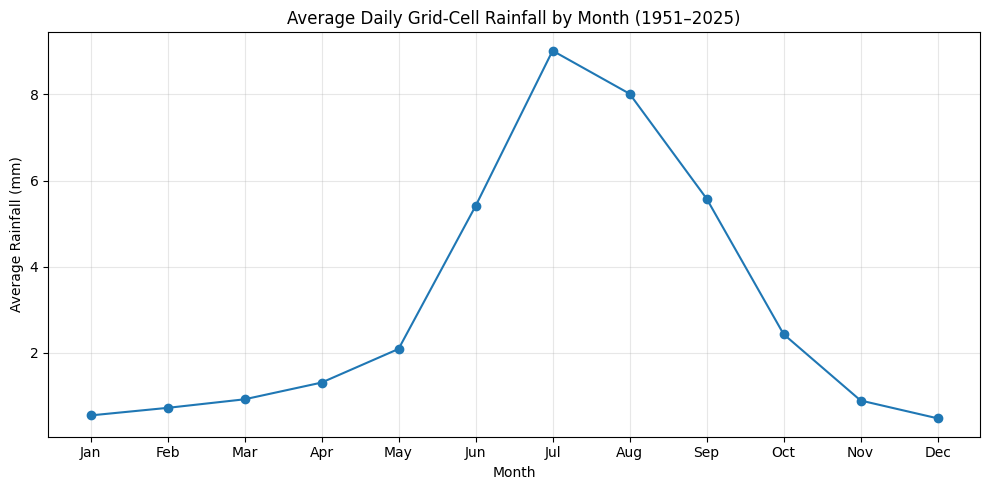

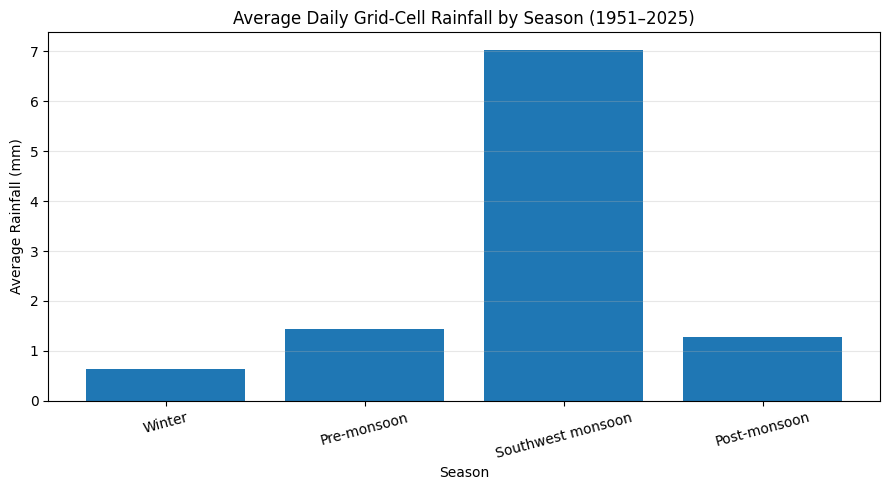

In [5]:
import matplotlib.pyplot as plt

# 1. Monthly rainfall line plot

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_summary.index,
    monthly_summary["mean_rainfall"],
    marker="o"
)

plt.title("Average Daily Grid-Cell Rainfall by Month (1951–2025)")
plt.xlabel("Month")
plt.ylabel("Average Rainfall (mm)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


# 2. Seasonal rainfall bar chart

plt.figure(figsize=(9, 5))

plt.bar(
    seasonal_summary.index,
    seasonal_summary["mean_rainfall"]
)

plt.title("Average Daily Grid-Cell Rainfall by Season (1951–2025)")
plt.xlabel("Season")
plt.ylabel("Average Rainfall (mm)")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
year_month_data = []

for year in range(START_YEAR, END_YEAR + 1):

    file_path = INTERIM_DIR / f"imd_rainfall_{year}.csv"

    for chunk in pd.read_csv(
        file_path,
        usecols=["date", "rainfall_mm"],
        parse_dates=["date"],
        chunksize=500_000
    ):
        chunk["year"] = chunk["date"].dt.year
        chunk["month"] = chunk["date"].dt.month

        summary = chunk.groupby(["year", "month"])["rainfall_mm"].agg(
            total_rainfall="sum",
            mean_rainfall="mean"
        )

        year_month_data.append(summary)

year_month_df = pd.concat(year_month_data)

# Combine chunk-level statistics correctly
year_month_summary = year_month_df.groupby(
    level=["year", "month"]
).agg(
    total_rainfall=("total_rainfall", "sum")
)

# Calculate the actual mean using total observations
observation_counts = []

for year in range(START_YEAR, END_YEAR + 1):
    file_path = INTERIM_DIR / f"imd_rainfall_{year}.csv"

    for chunk in pd.read_csv(
        file_path,
        usecols=["date", "rainfall_mm"],
        parse_dates=["date"],
        chunksize=500_000
    ):
        counts = chunk.groupby(
            [chunk["date"].dt.year, chunk["date"].dt.month]
        )["rainfall_mm"].count()

        observation_counts.append(counts)

year_month_counts = pd.concat(observation_counts).groupby(level=[0, 1]).sum()

year_month_summary["mean_rainfall"] = (
    year_month_summary["total_rainfall"] / year_month_counts
)

# Convert to year × month format
heatmap_data = year_month_summary["mean_rainfall"].unstack()

heatmap_data.columns = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

display(heatmap_data.head())

,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
year,,,,,,,,,,,,
1951,0.467125,0.372081,1.314266,1.641981,1.872602,4.850341,7.694918,6.792567,3.842638,2.171004,1.164144,0.123162
1952,0.281017,0.597667,1.066351,1.065972,2.202673,5.393508,8.820968,7.857140,4.026696,2.433282,0.239259,0.630134
1953,0.851143,0.347200,0.915080,1.140604,1.584743,5.154589,9.906300,9.137482,5.628432,2.604709,0.378818,0.224535
1954,1.009341,1.122098,0.544128,0.965482,1.880967,4.825469,9.309326,7.181675,7.704989,2.352184,0.132678,0.489364
1955,0.690353,0.163997,0.937486,1.061978,2.312010,5.742424,7.613895,9.598922,6.916385,4.603321,0.764889,0.324274


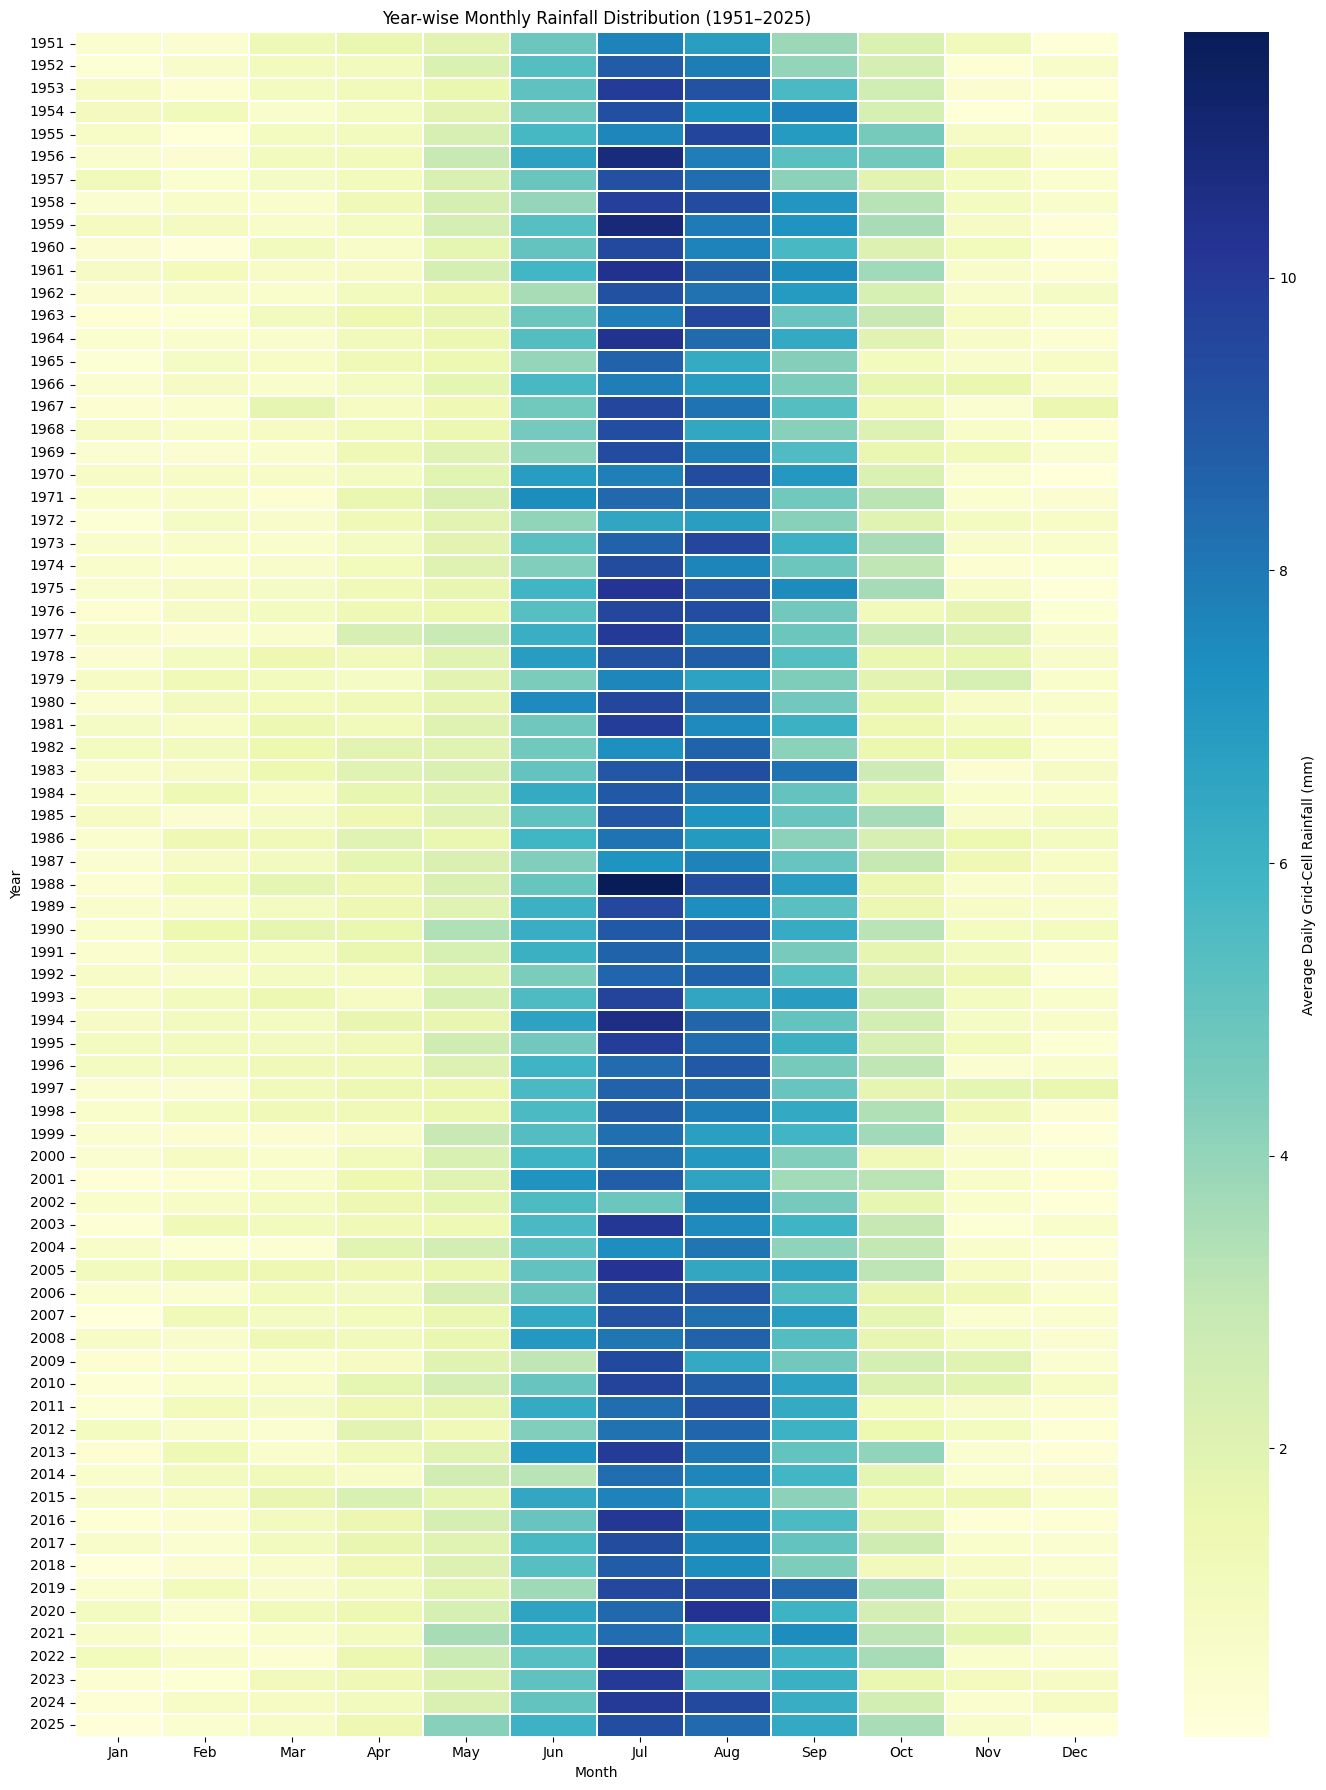

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 18))

sns.heatmap(
    heatmap_data,
    cmap="YlGnBu",
    linewidths=0.1,
    cbar_kws={"label": "Average Daily Grid-Cell Rainfall (mm)"}
)

plt.title("Year-wise Monthly Rainfall Distribution (1951–2025)")
plt.xlabel("Month")
plt.ylabel("Year")
plt.tight_layout()
plt.show()

In [8]:
#annual rainfal analysis
annual_results = []

for year in range(START_YEAR, END_YEAR + 1):

    file_path = INTERIM_DIR / f"imd_rainfall_{year}.csv"

    total_rainfall = 0
    total_observations = 0

    for chunk in pd.read_csv(
        file_path,
        usecols=["rainfall_mm"],
        chunksize=500_000
    ):
        total_rainfall += chunk["rainfall_mm"].sum()
        total_observations += chunk["rainfall_mm"].count()

    annual_results.append({
        "year": year,
        "mean_rainfall": total_rainfall / total_observations,
        "total_observations": total_observations
    })

annual_summary = pd.DataFrame(annual_results)

display(annual_summary.head())

,year,mean_rainfall,total_observations
0,1951,2.709305,1811860
1,1952,2.899273,1816824
2,1953,3.180106,1811860
3,1954,3.139873,1811860
4,1955,3.418220,1811860


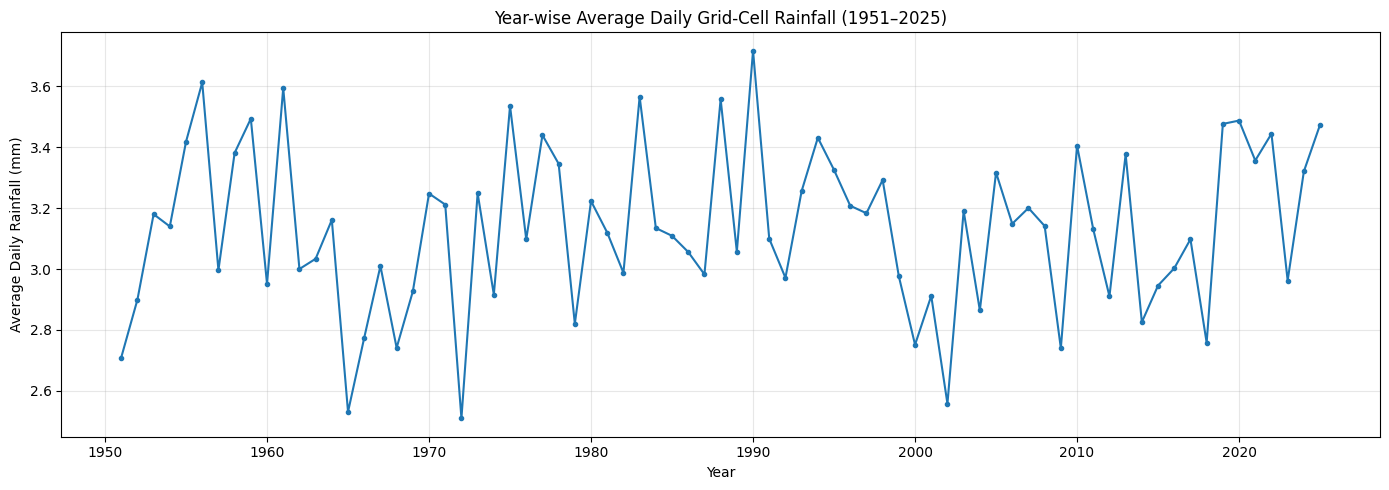

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))

plt.plot(
    annual_summary["year"],
    annual_summary["mean_rainfall"],
    marker="o",
    markersize=3
)

plt.title("Year-wise Average Daily Grid-Cell Rainfall (1951–2025)")
plt.xlabel("Year")
plt.ylabel("Average Daily Rainfall (mm)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

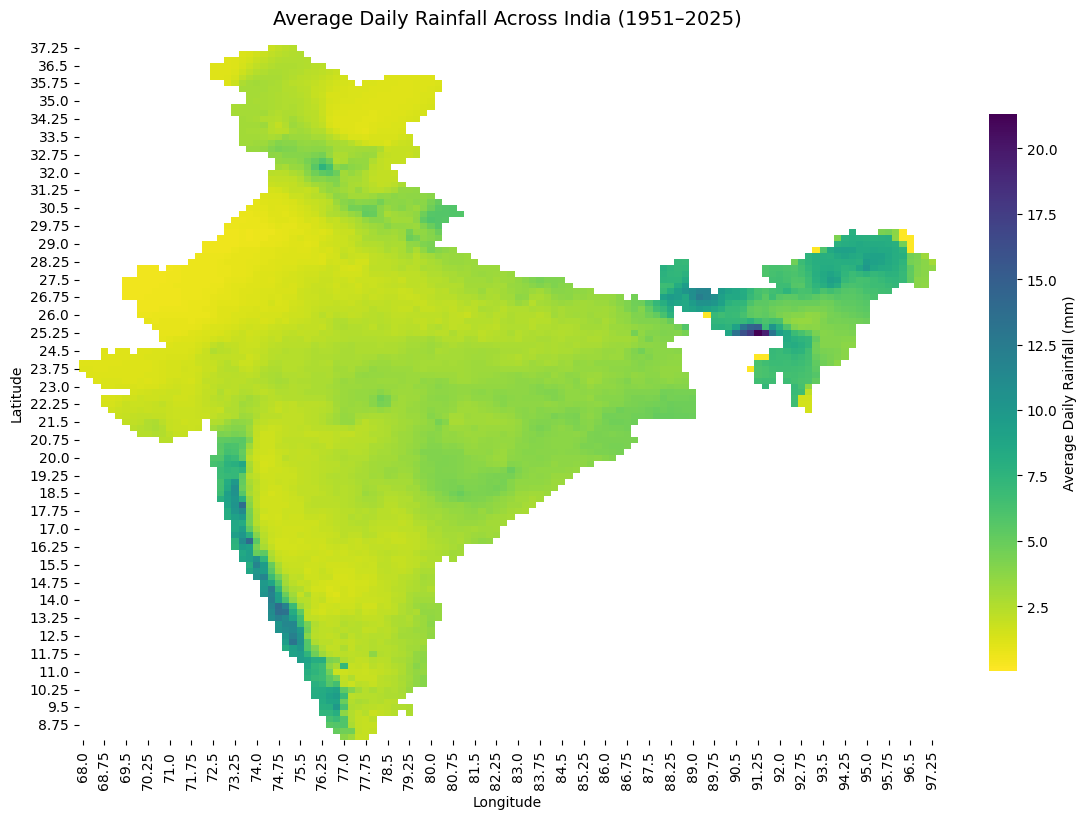

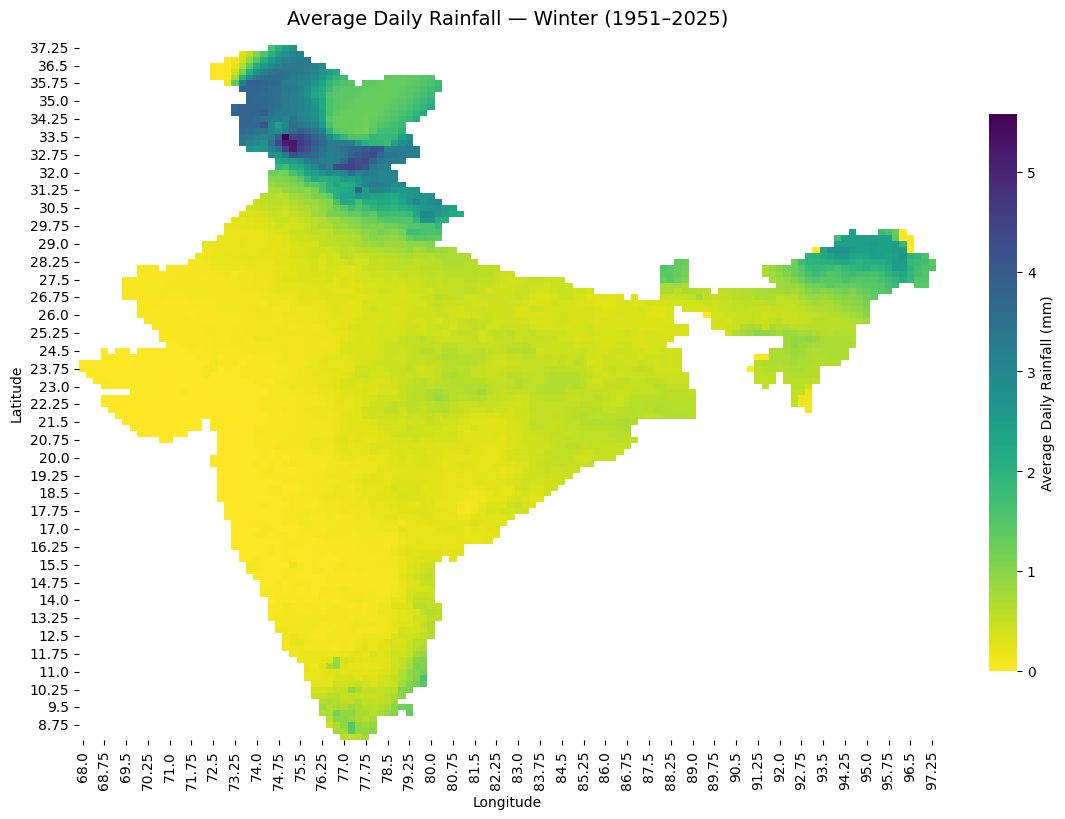

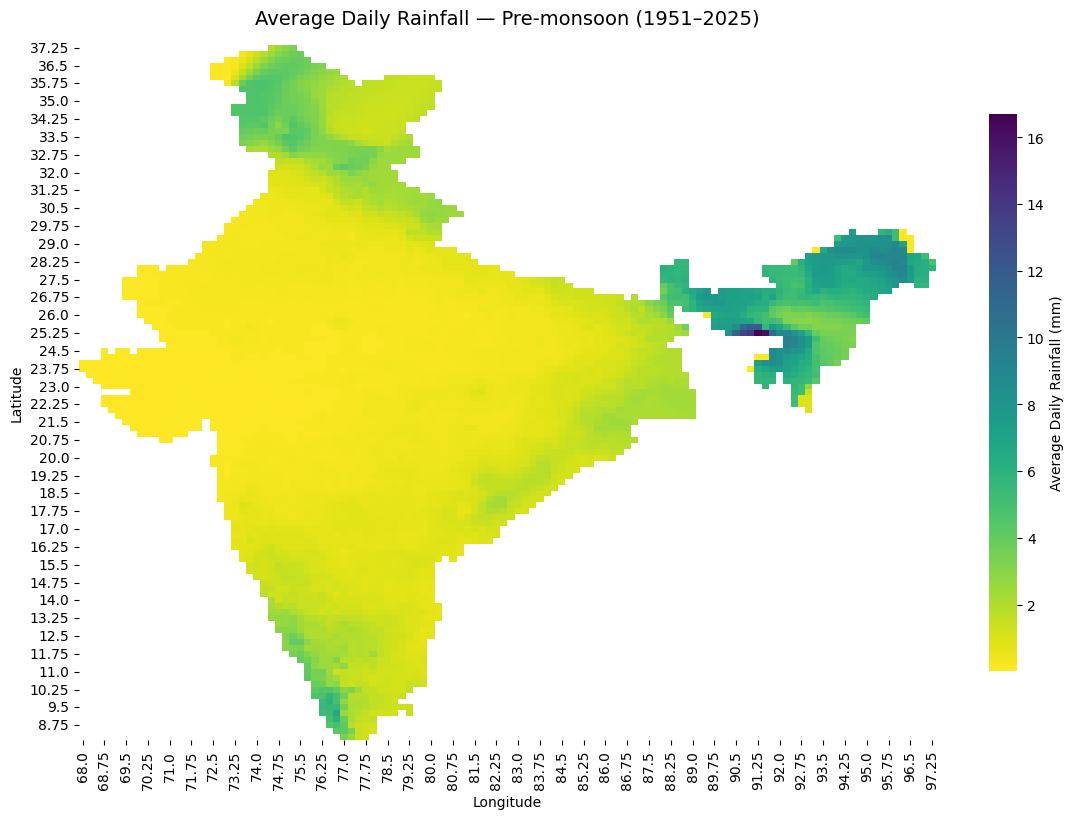

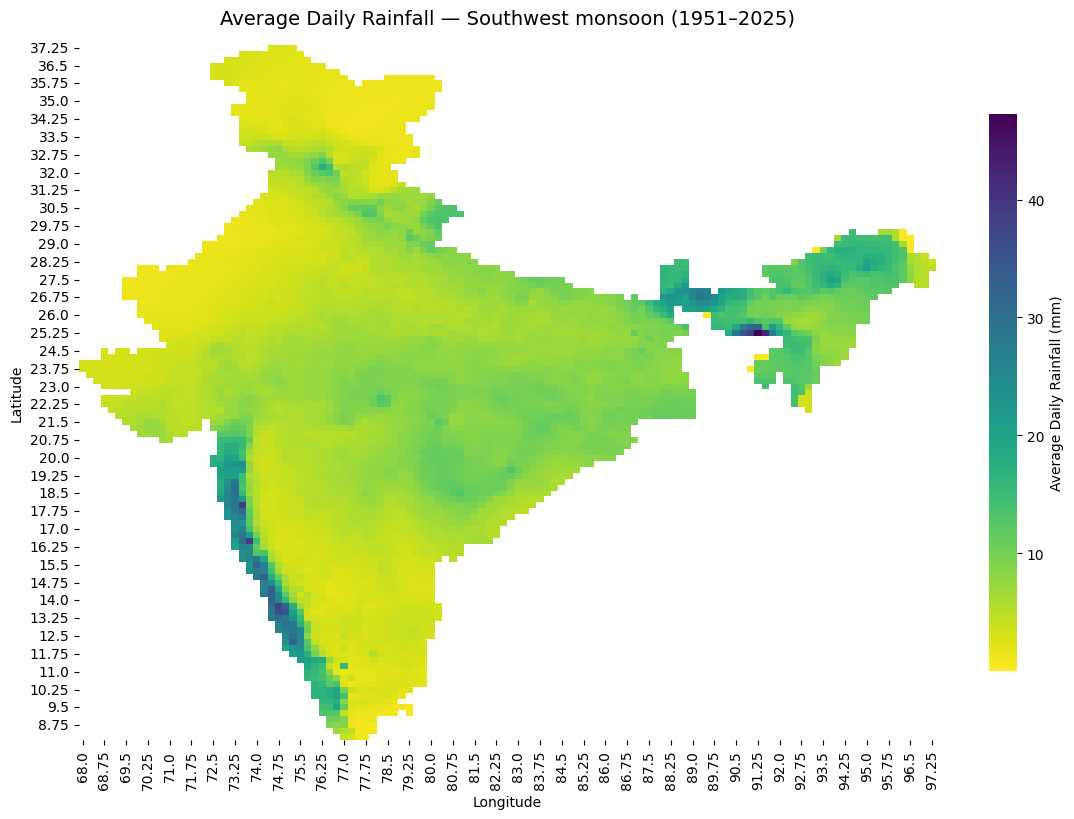

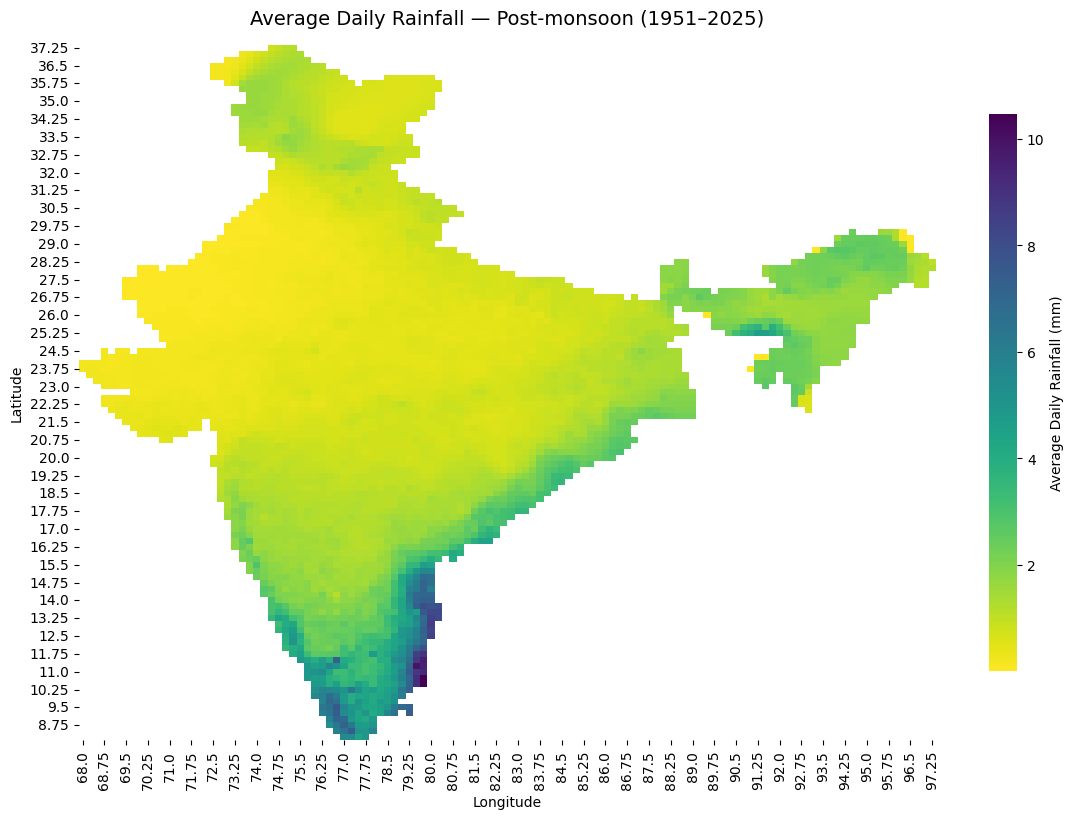

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

spatial_data = []

season_mapping = {
    1: "Winter", 2: "Winter",
    3: "Pre-monsoon", 4: "Pre-monsoon", 5: "Pre-monsoon",
    6: "Southwest monsoon", 7: "Southwest monsoon",
    8: "Southwest monsoon", 9: "Southwest monsoon",
    10: "Post-monsoon", 11: "Post-monsoon", 12: "Post-monsoon"
}

# Read all years and calculate rainfall totals and counts
for year in range(START_YEAR, END_YEAR + 1):

    file_path = INTERIM_DIR / f"imd_rainfall_{year}.csv"

    for chunk in pd.read_csv(
        file_path,
        usecols=["date", "latitude", "longitude", "rainfall_mm"],
        parse_dates=["date"],
        chunksize=500_000
    ):

        chunk["season"] = chunk["date"].dt.month.map(season_mapping)

        summary = chunk.groupby(
            ["latitude", "longitude", "season"]
        )["rainfall_mm"].agg(
            total_rainfall="sum",
            observations="count"
        )

        spatial_data.append(summary)

# Combine all chunks and years
spatial_df = pd.concat(spatial_data)

spatial_summary = spatial_df.groupby(
    level=["latitude", "longitude", "season"]
).sum()

spatial_summary["mean_rainfall"] = (
    spatial_summary["total_rainfall"] /
    spatial_summary["observations"]
)

# Annual average: combine all seasons for each grid cell
annual_summary = spatial_summary.groupby(
    level=["latitude", "longitude"]
)[["total_rainfall", "observations"]].sum()

annual_summary["mean_rainfall"] = (
    annual_summary["total_rainfall"] /
    annual_summary["observations"]
)

# Prepare annual and seasonal grids
annual_grid = annual_summary["mean_rainfall"].unstack(
    level="longitude"
).sort_index(ascending=False)

season_order = [
    "Winter",
    "Pre-monsoon",
    "Southwest monsoon",
    "Post-monsoon"
]

seasonal_grids = {}

for season in season_order:

    season_data = spatial_summary.xs(
        season,
        level="season"
    )

    seasonal_grids[season] = season_data[
        "mean_rainfall"
    ].unstack(level="longitude").sort_index(ascending=False)


# Generate A4-landscape-style heatmaps
def plot_spatial_heatmap(data, title):

    fig, ax = plt.subplots(figsize=(11.7, 8.3))

    sns.heatmap(
        data,
        cmap="viridis_r",
        linewidths=0,
        ax=ax,
        cbar_kws={
            "label": "Average Daily Rainfall (mm)",
            "shrink": 0.8
        }
    )

    ax.set_title(title, fontsize=14, pad=15)
    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")

    plt.tight_layout()
    plt.show()


# Annual map
plot_spatial_heatmap(
    annual_grid,
    "Average Daily Rainfall Across India (1951–2025)"
)

# Seasonal maps
for season in season_order:

    plot_spatial_heatmap(
        seasonal_grids[season],
        f"Average Daily Rainfall — {season} (1951–2025)"
    )

As seen from the above graphs, peak monsoon times for different regions in india accour during different climatic seasons. 
Hence, Precipitation anomalies should be calculated relative to the historical rainfall climatology of the individual grid cell and the corresponding time of year.

Therefore we should preserve both:
- Spatial differences to know what is normal for each location.
- Seasonal differences to know what is normal for that location during that particular season or month.


Fron the above analysis, seasonal maps are useful, but the considered four broad seasons are analytical groupings. They don't necessarily capture every regional monsoon system or its exact onset and withdrawal.


In [14]:
monthly_sd_data = []

for year in range(START_YEAR, END_YEAR + 1):

    file_path = INTERIM_DIR / f"imd_rainfall_{year}.csv"

    for chunk in pd.read_csv(
        file_path,
        usecols=["date", "latitude", "longitude", "rainfall_mm"],
        parse_dates=["date"],
        chunksize=500_000
    ):
        chunk["month"] = chunk["date"].dt.month

        summary = chunk.groupby(
            ["latitude", "longitude", "month"]
        )["rainfall_mm"].agg(
            count="count",
            mean="mean",
            std="std"
        )

        monthly_sd_data.append(summary)

# Combine chunk-level statistics correctly
sd_df = pd.concat(monthly_sd_data)

def combine_statistics(group):
    n = group["count"].sum()
    mean = (group["count"] * group["mean"]).sum() / n

    # Combine variances, accounting for differences between chunk means
    variance = (
        (
            (group["count"] - 1) * group["std"].fillna(0) ** 2
            + group["count"] * (group["mean"] - mean) ** 2
        ).sum() / (n - 1)
    )

    return pd.Series({
        "mean_rainfall": mean,
        "std_rainfall": np.sqrt(variance),
        "observations": n
    })

monthly_sd_summary = sd_df.groupby(
    level=["latitude", "longitude", "month"]
).apply(combine_statistics)

display(monthly_sd_summary.head())

mean_rainfall  std_rainfall  observations
latitude longitude month                                           
8.25     77.0      1           0.532076      2.845653        2325.0
                   2           0.686294      3.358916        2119.0
                   3           1.221292      4.605372        2325.0
                   4           3.635905      8.034368        2250.0
                   5           5.465188     12.306517        2325.0

Why we calculated standard deviation
- Monthly, grid-cell-specific SD: Measures how much rainfall fluctuates across years for a particular month and location.
- Why it's useful: Helps determine whether a rainfall deviation is unusually large relative to that location's historical variability.
- How we'll use it: As a reference when calculating standardised precipitation anomalies.

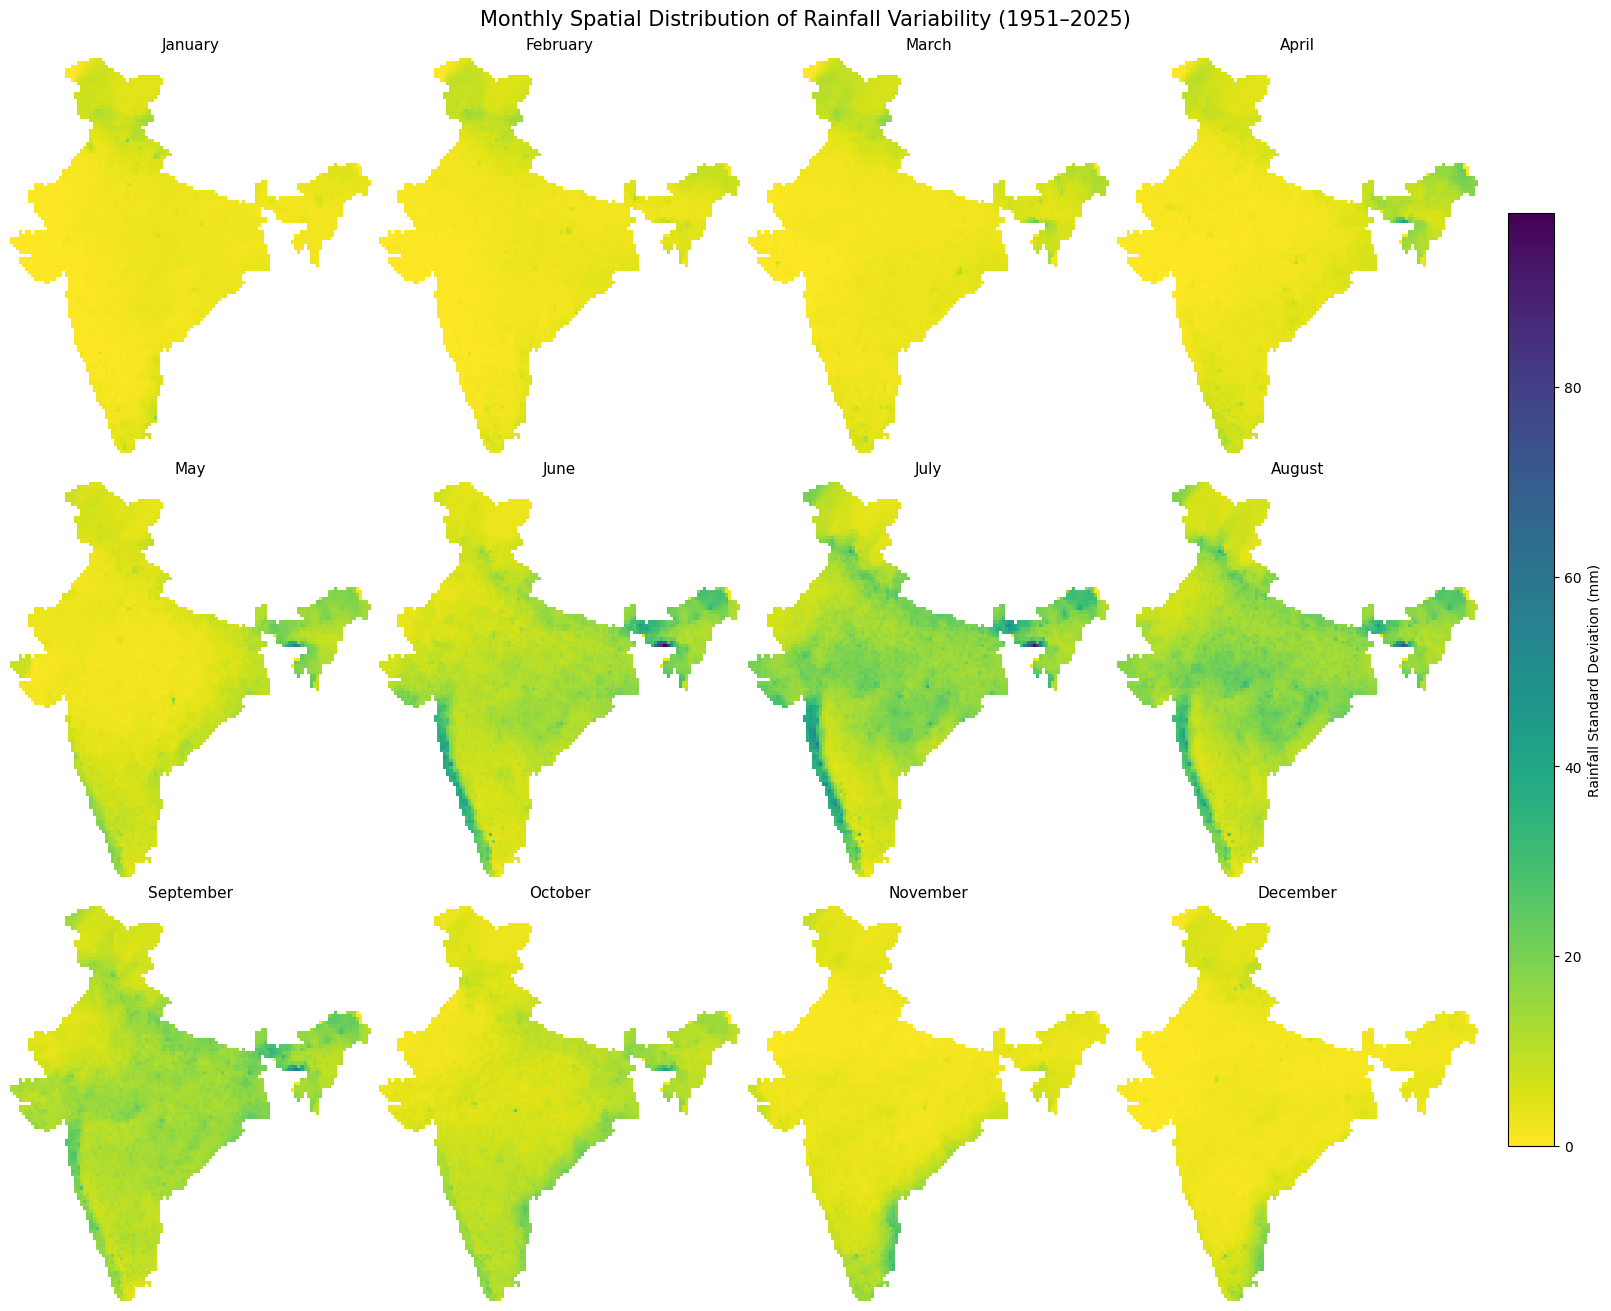

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

months = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

max_sd = monthly_sd_summary["std_rainfall"].max()

fig, axes = plt.subplots(
    3, 4,
    figsize=(16, 13),
    constrained_layout=True
)

for month in range(1, 13):

    ax = axes[(month - 1) // 4, (month - 1) % 4]

    month_data = monthly_sd_summary.xs(
        month, level="month"
    )

    month_grid = month_data["std_rainfall"].unstack(
        level="longitude"
    ).sort_index(ascending=False)

    sns.heatmap(
        month_grid,
        cmap="viridis_r",
        vmin=0,
        vmax=max_sd,
        cbar=False,
        xticklabels=False,
        yticklabels=False,
        ax=ax
    )

    ax.set_title(months[month - 1], fontsize=11)
    ax.set_xlabel("")
    ax.set_ylabel("")

# One shared colour bar outside all 12 maps
sm = plt.cm.ScalarMappable(
    cmap="viridis_r",
    norm=plt.Normalize(vmin=0, vmax=max_sd)
)
sm.set_array([])

fig.colorbar(
    sm,
    ax=axes,
    location="right",
    shrink=0.75,
    pad=0.02,
    label="Rainfall Standard Deviation (mm)"
)

fig.suptitle(
    "Monthly Spatial Distribution of Rainfall Variability (1951–2025)",
    fontsize=15
)

plt.show()

Monthly SD maps (above)

Purpose: Shows the historical rainfall variability for every grid cell separately for each calendar month. This helps identify which regions experience greater year-to-year fluctuations during different months.

Interpretation: Darker areas indicate greater year-to-year rainfall fluctuations, while lighter areas indicate more consistent rainfall. Comparing the 12 maps reveals how rainfall variability changes across regions throughout the year.

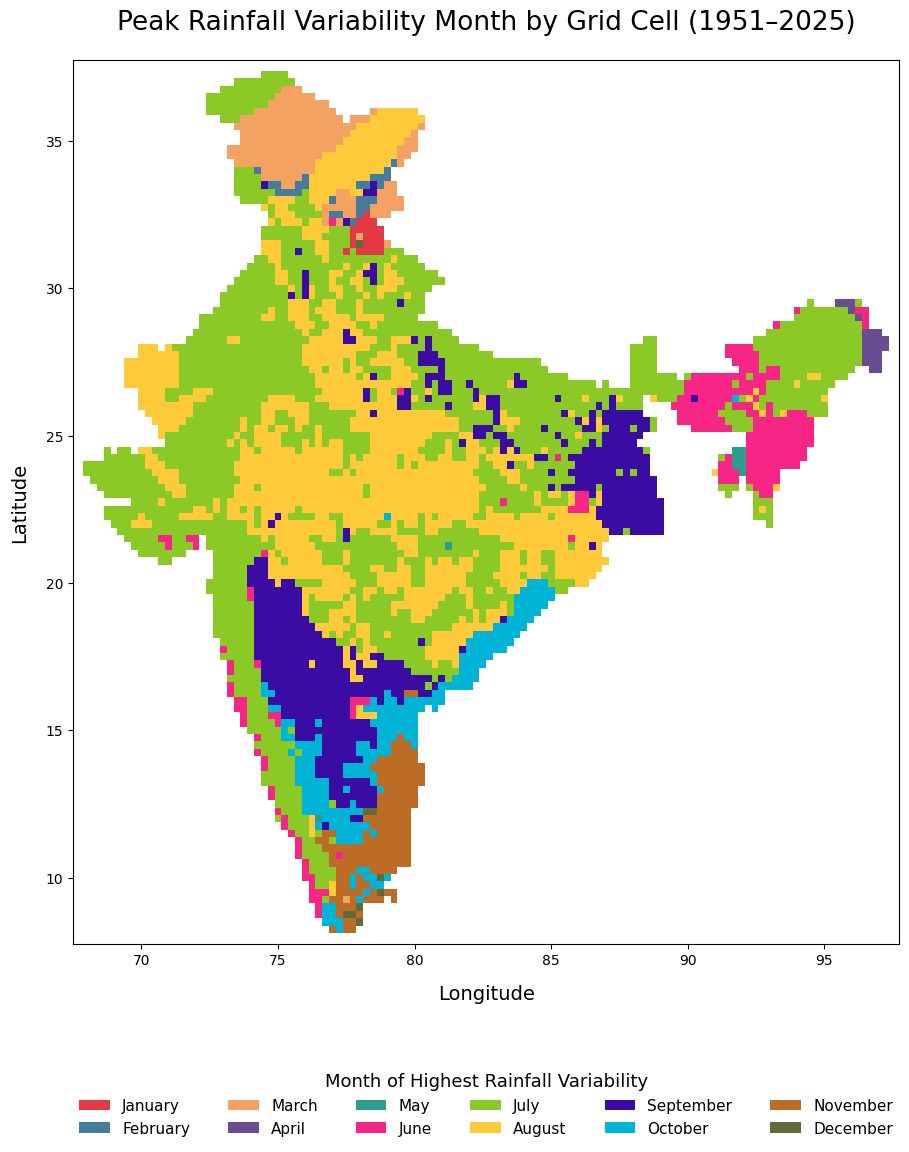

In [23]:
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Patch
import numpy as np

# Completely new, distinct colour palette
month_colors = [
    "#E63946",  # January - Red
    "#457B9D",  # February - Blue
    "#F4A261",  # March - Orange
    "#6A4C93",  # April - Purple
    "#2A9D8F",  # May - Teal
    "#F72585",  # June - Pink
    "#8AC926",  # July - Lime green
    "#FFCA3A",  # August - Yellow
    "#3A0CA3",  # September - Deep purple
    "#00B4D8",  # October - Cyan
    "#BC6C25",  # November - Brown
    "#606C38"   # December - Olive
]

cmap = mcolors.ListedColormap(month_colors)

norm = mcolors.BoundaryNorm(
    np.arange(0.5, 13.5, 1),
    cmap.N
)

fig, ax = plt.subplots(figsize=(16, 13))

ax.pcolormesh(
    peak_month_grid.columns,
    peak_month_grid.index,
    peak_month_grid.values,
    cmap=cmap,
    norm=norm,
    shading="nearest"
)

# Add padding so no part of India is clipped
ax.set_xlim(
    peak_month_grid.columns.min() - 0.5,
    peak_month_grid.columns.max() + 0.5
)

ax.set_ylim(
    peak_month_grid.index.min() - 0.5,
    peak_month_grid.index.max() + 0.5
)

# Geographical aspect ratio
ax.set_aspect(1 / np.cos(np.deg2rad(22)))

ax.set_title(
    "Peak Rainfall Variability Month by Grid Cell (1951–2025)",
    fontsize=19,
    pad=22
)

ax.set_xlabel("Longitude", fontsize=14, labelpad=12)
ax.set_ylabel("Latitude", fontsize=14, labelpad=12)

# Month legend
month_labels = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

legend_handles = [
    Patch(facecolor=month_colors[i], label=month_labels[i])
    for i in range(12)
]

ax.legend(
    handles=legend_handles,
    title="Month of Highest Rainfall Variability",
    title_fontsize=13,
    fontsize=11,
    loc="upper center",
    bbox_to_anchor=(0.5, -0.13),
    ncol=6,
    frameon=False,
    columnspacing=2.5
)

plt.subplots_adjust(
    left=0.10,
    right=0.97,
    top=0.90,
    bottom=0.22
)

plt.show()

Peak variability month map (above)

Purpose: Identifies the month in which rainfall has the highest historical standard deviation at each grid cell. This helps identify when different regions experience their greatest rainfall fluctuations.

Interpretation: Each grid cell is coloured according to its month of highest rainfall variability. Different colours reveal which months experience the greatest year-to-year rainfall fluctuations across different geographical regions.


Fron the above analysis, seasonal maps are useful, but the considered four broad seasons are analytical groupings. They don't necessarily capture every regional monsoon system or its exact onset and withdrawal.

## Points to consider during feature engineering

A. Grid-cell-specific monthly climatology

- Calculate historical rainfall averages for each month at every grid cell.
- Needed to calculate location-specific monthly anomalies instead of comparing every location against the same baseline.

B. Peak rainfall month

- Identify the month receiving the highest average rainfall at each grid cell.
- Helps capture regional differences in peak rainfall periods.

C. Dominant rainfall season

- Identify which season contributes the largest share of annual rainfall at each grid cell.
- Helps distinguish regions dominated by different monsoon systems.

D. Monthly rainfall variability

- Calculate historical rainfall variability for each grid cell and month.
- Helps determine whether a rainfall deviation is significant relative to that location's normal fluctuations.

E. Regional rainfall onset and withdrawal

- Consider location-specific rainfall onset, peak and withdrawal periods.
- Helps avoid relying entirely on fixed calendar seasons.

These need to be revisited during feature engineering to decide which are actual model features and which are used for anomaly calculation or interpretation.